In [1]:
import array
from time import perf_counter
import collections
import matplotlib.pyplot as plt
from tqdm import tqdm

# Exercice 1

In [2]:
class ListeSimplementChainee:

    # Classe qui implémente les chaînons 
    class Chainon:
        def __init__(self, valeur, suivant = None):
            self.valeur = valeur
            self.suivant = suivant

    # classe qui définit un itérateur sur les listes simplement chaînées
    class Iterateur:
        def __init__(self, chainon):
            self._chainon = chainon
            
        def __iter__(self):
            return self
    
        def __next__(self):
            if self._chainon is None:
                raise StopIteration
            else:
                valeur = self._chainon.valeur
                self._chainon = self._chainon.suivant
                return valeur
    
    def __init__(self):
        self.__premier = None
        self.__taille = 0

    def append(self, valeur):
        self.__premier = ListeSimplementChainee.Chainon(valeur, self.__premier) # L'ancien premier élément de la chaine devient le suivant du nouveau premier
        self.__taille += 1
        

    def pop(self):
        if self.__premier is not None:
            valeur = self.__premier.valeur
            self.__premier = self.__premier.suivant
            self.__taille = self.__taille - 1
            return valeur
        else:
            return None

    def __len__(self):
        return self.__taille

    def __iter__(self):
        return ListeSimplementChainee.Iterateur(self.__premier)

In [3]:
# Instanciation d'un objet de type ListeSimplementChainee

l = ListeSimplementChainee()

# On doit observer une liste vide :

print("Longueur de la liste l initialisée : ", len(l))

for x in l:
    print(x)

Longueur de la liste l initialisée :  0


In [4]:
# Vérifions que la méthode append fonctionne :

l.append(1)
l.append(2)
l.append(3)
l.append(4)

for x in l:
    print(x)

4
3
2
1


In [5]:
# Puis que la méthode pop est aussi fonctionnelle : 

taille_initiale = len(l)

for i in range(taille_initiale):
    valeur_depilee = l.pop()
    print("Valeur dépilée :", valeur_depilee, ". Nouvelle taille de la liste simplement chaînée :", len(l))

Valeur dépilée : 4 . Nouvelle taille de la liste simplement chaînée : 3
Valeur dépilée : 3 . Nouvelle taille de la liste simplement chaînée : 2
Valeur dépilée : 2 . Nouvelle taille de la liste simplement chaînée : 1
Valeur dépilée : 1 . Nouvelle taille de la liste simplement chaînée : 0


In [6]:
# Et si l'on essaie de dépiler une liste vide :
print(l.pop())

None


# Exercice 2

In [7]:
class Pile:
    def __init__(self, conteneur):
        self.__conteneur = conteneur

    def push(self, valeur):
        self.__conteneur.append(valeur)

    def pop(self):
        self.__conteneur.pop()

    def __len__(self):
        return len(self.__conteneur)

def compare_piles(n):
    conteneurs = [ListeSimplementChainee(), array.array('l'), list(), collections.deque()]
    
    for conteneur in conteneurs:
        print(" ------ Conteneur \"" + type(conteneur).__name__ + "\" ------")

        debut = perf_counter()
        p = Pile(conteneur)
        
        for i in range(n):
            p.push(i)

        while(len(l) > 0):
            p.pop()

        print("Temps mis par le conteneur pour empiler et dépiler " + str(n) + " éléments : " + str(perf_counter() - debut))

def compare_piles_pour_affichage(n):
    conteneurs = [ListeSimplementChainee(), array.array('l'), list(), collections.deque()]
    temps = []
    for conteneur in conteneurs:
        debut = perf_counter()
        p = Pile(conteneur)
        
        for i in range(n):
            p.push(i)

        while(len(l) > 0):
            p.pop()

        temps.append(perf_counter() - debut) 
    return temps

In [8]:
valeurs_n = [1]
for i in range(1, 7):
    for k in [0.2, 0.4, 0.6, 0.8, 1]:
        valeurs_n.append(int(k * 10 ** i))

valeurs_n.sort()
print(valeurs_n)

tous_temps =  []

for n in tqdm(valeurs_n):
    temps = compare_piles_pour_affichage(n)
    tous_temps.append(temps)

temps_liste_simplementchainee = [temps[0] for temps in tous_temps]
temps_array = [temps[1] for temps in tous_temps]
temps_list = [temps[2] for temps in tous_temps]
temps_deque = [temps[3] for temps in tous_temps]

[1, 2, 4, 6, 8, 10, 20, 40, 60, 80, 100, 200, 400, 600, 800, 1000, 2000, 4000, 6000, 8000, 10000, 20000, 40000, 60000, 80000, 100000, 200000, 400000, 600000, 800000, 1000000]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 31/31 [00:04<00:00,  6.69it/s]


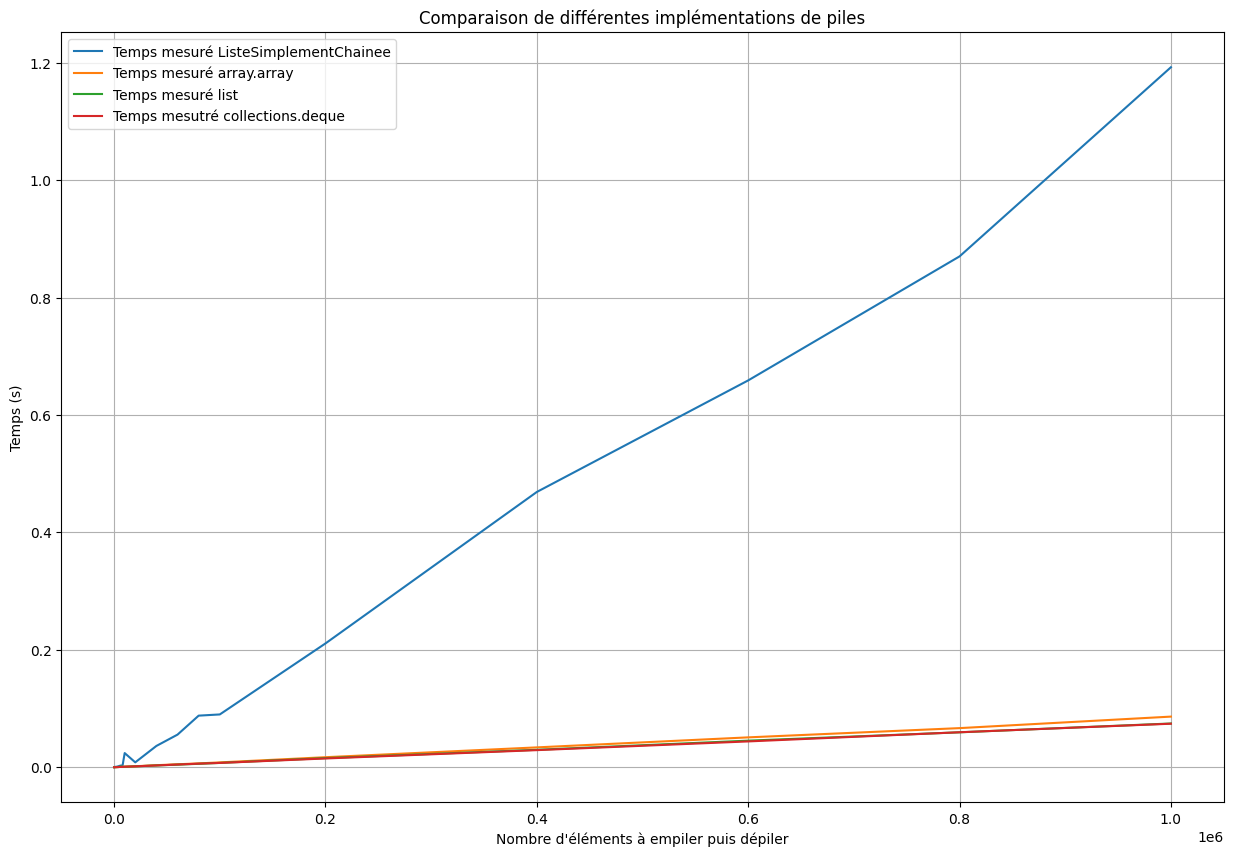

In [9]:
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(valeurs_n, temps_liste_simplementchainee, label="Temps mesuré ListeSimplementChainee")
ax.plot(valeurs_n, temps_array, label="Temps mesuré array.array")
ax.plot(valeurs_n, temps_list, label="Temps mesuré list")
ax.plot(valeurs_n, temps_deque, label="Temps mesutré collections.deque")

ax.set(xlabel="Nombre d'éléments à empiler puis dépiler", ylabel="Temps (s)", title="Comparaison de différentes implémentations de piles")
ax.grid()
plt.legend()

plt.show()

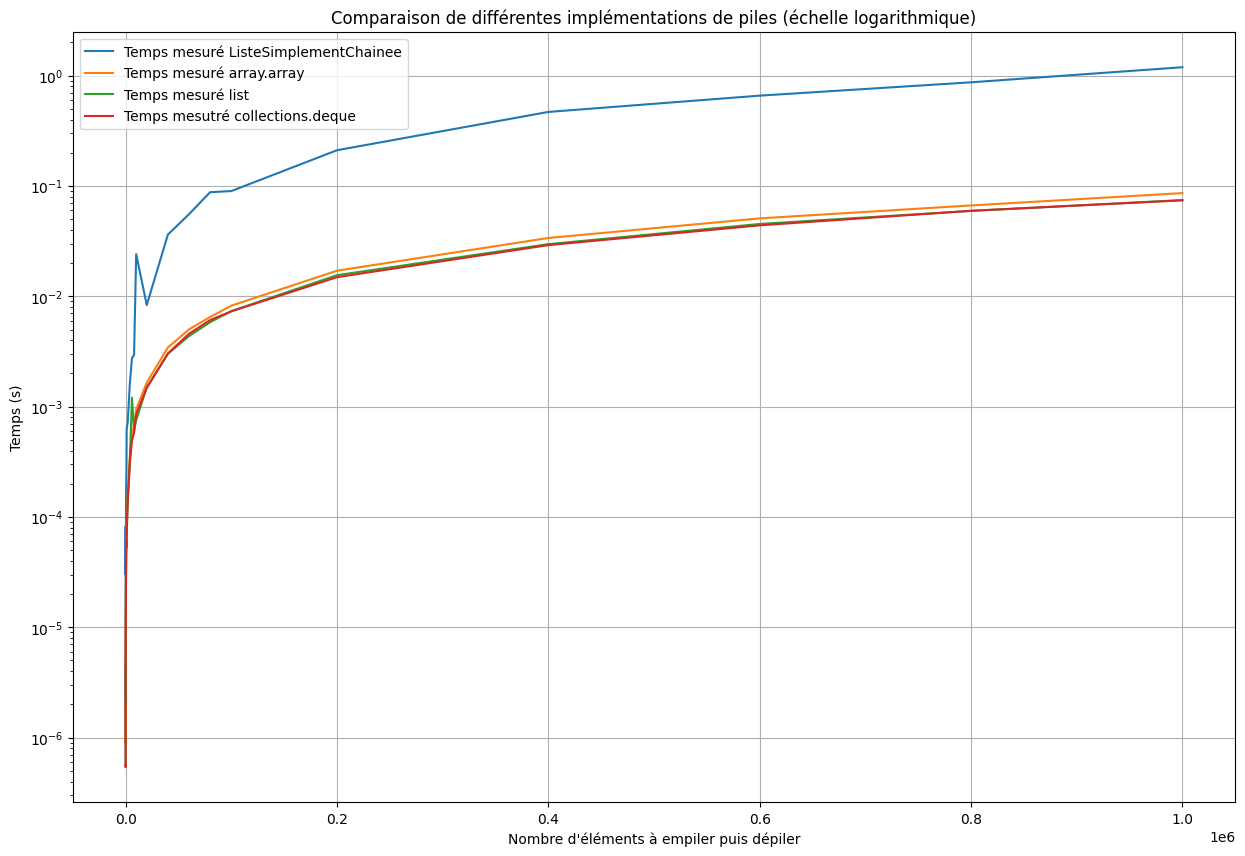

In [10]:
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(valeurs_n, temps_liste_simplementchainee, label="Temps mesuré ListeSimplementChainee")
ax.plot(valeurs_n, temps_array, label="Temps mesuré array.array")
ax.plot(valeurs_n, temps_list, label="Temps mesuré list")
ax.plot(valeurs_n, temps_deque, label="Temps mesutré collections.deque")

ax.set(xlabel="Nombre d'éléments à empiler puis dépiler", ylabel="Temps (s)", title="Comparaison de différentes implémentations de piles (échelle logarithmique)")
ax.grid()
ax.set_yscale('log')
plt.legend()

plt.show()